### scikit-learn 2: Klassifikation - Übungen

Im ersten Notebook hast du mit k-nächsten Nachbarn das Grundmuster `fit`, `predict`, `score` kennengelernt. Hier lernst du weitere Verfahren
für die **Klassifikation** kennen: Entscheidungsbäume, die logistische Regression und neuronale Netze. Außerdem geht es darum, wie man ein Modell
fair bewertet (Kreuzvalidierung), wie man gute Einstellungen findet (Gittersuche) und warum die Genauigkeit allein manchmal täuscht.

Die Reihe hat vier Notebooks:

1. Grundlagen: Merkmale und Zielwerte, das erste Modell, Trainings- und Testdaten, Skalieren
2. **Klassifikation**: k-nächste Nachbarn, Entscheidungsbäume, logistische Regression, neuronale Netze, Kreuzvalidierung (dieses Notebook)
3. Regression: Zahlen vorhersagen, Überanpassung
4. Unüberwachtes Lernen: Clustering, Dimensionen reduzieren, Ziffernerkennung

Vorausgesetzt wird *scikit-learn: Grundlagen*.

**Tabellen anzeigen:** Steht eine Tabelle (ein DataFrame) in der **letzten Zeile** einer Zelle, zeigt JupyterLab sie als Tabelle an. Mehrere Tabellen
in einer Zelle zeigt man mit `display(df)` an. Einzelne Werte gibt man wie gewohnt mit `print()` aus. Die erwarteten Ausgaben in den Aufgaben sehen genauso aus.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Beim ersten `import sklearn` lädt der Browser die Pakete nach. Das dauert einige Sekunden.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

#### Beispieldaten anlegen

**Führe diese Zelle zuerst aus.** Sie legt die Datei `iris.csv`: die berühmten Iris-Daten von 1936, 150 vermessene Schwertlilien von drei Arten (*setosa*, *versicolor*, *virginica*).
  Gemessen sind Länge und Breite des **Kelchblatts** und des **Blütenblatts** in cm.

Die erste Zeile blendet eine harmlose Meldung aus, die das Python im Browser sonst beim ersten Training anzeigt.

In [ ]:
import warnings
warnings.filterwarnings('ignore', message='JsProxy')   # harmlose Meldung des Browser-Pythons ausblenden

from sklearn.datasets import load_iris

iris = load_iris(as_frame=True).frame
iris.columns = ['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite', 'art']
iris['art'] = iris['art'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
iris.to_csv('iris.csv', index=False)
print('Angelegt: iris.csv')

## 1. k-nächste Nachbarn: Wie groß soll k sein?

#### Übungsdaten mit `make_moons`

`make_moons(n_samples=200, noise=0.3, random_state=0)` aus `sklearn.datasets` erzeugt zwei ineinandergreifende **Halbmonde** aus Punkten (Klasse 0 und 1).
`noise` gibt an, wie stark die Punkte zufällig verstreut sind, `random_state` legt den Zufall fest. Die beiden Merkmale sind ein Array,
das man mit `pd.DataFrame(X, columns=['x1', 'x2'])` in eine Tabelle mit Spaltennamen umwandelt. `y` ist ein Array aus Nullen und Einsen.

Solche erfundenen Daten sind praktisch, um Verfahren zu vergleichen: Man sieht im Diagramm sofort, wie schwer die Aufgabe ist.

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
import matplotlib.pyplot as plt

print(X.shape, y[:10])
plt.scatter(X['x1'], X['x2'], c=y, cmap='coolwarm', s=15)
plt.show()

#### Überanpassung und Unteranpassung

- Mit **kleinem** `k` (z. B. 1) folgt das Modell jedem einzelnen Punkt, auch den zufällig verstreuten. Es lernt die Trainingsdaten auswendig, mit allen Zufällen.
  Das heißt **Überanpassung** (*overfitting*): auf den Trainingsdaten sehr gut, auf neuen Daten schlechter.
- Mit **sehr großem** `k` wird die Grenze zu grob, das Modell erkennt die Form der Daten nicht mehr: **Unteranpassung** (*underfitting*).

Dazwischen liegt ein gutes `k`. Im Diagramm sieht man das an den Entscheidungsgrenzen.

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

for i, k in enumerate([1, 15, 100], start=1):
    modell = KNeighborsClassifier(n_neighbors=k)
    modell.fit(X_train, y_train)
    print(f'k = {k}: Training {modell.score(X_train, y_train):.3f}, Test {modell.score(X_test, y_test):.3f}')
    ax = plt.subplot(1, 3, i)
    DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3, cmap='coolwarm', ax=ax)
    ax.scatter(X_train['x1'], X_train['x2'], c=y_train, cmap='coolwarm', s=8)
    ax.set_title(f'k = {k}')
plt.show()

#### Aufgabe 1.1

Gib aus, wie viele Punkte jede Klasse in den Halbmond-Daten hat (`np.bincount(y)`) und wie viele Trainings- und Testpunkte es sind.

**Erwartete Ausgabe:**

```
[100 100]
140 60
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
import numpy as np
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
import numpy as np
print(np.bincount(y))
print(len(X_train), len(X_test))
```

</details>

#### Aufgabe 1.2

Gib für `k` = 1, 3, 5, 9, 15, 25, 50 und 100 die Genauigkeit auf Trainings- und Testdaten aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1 1.000 0.900
3 0.943 0.933
5 0.900 0.933
9 0.900 0.933
15 0.900 0.950
25 0.907 0.917
50 0.836 0.867
100 0.764 0.767
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
for k in [1, 3, 5, 9, 15, 25, 50, 100]:
    modell = KNeighborsClassifier(n_neighbors=k)
    modell.fit(X_train, y_train)
    print(f'{k} {modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 1.3

Suche unter `k` von 1 bis 40 das `k` mit der besten Test-Genauigkeit (bei Gleichstand das kleinste) und gib es mit der Genauigkeit aus.

**Erwartete Ausgabe:**

```
6 0.950
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
bestes_k = 0
beste = 0
for k in range(1, 41):
    modell = KNeighborsClassifier(n_neighbors=k)
    modell.fit(X_train, y_train)
    genauigkeit = modell.score(X_test, y_test)
    if genauigkeit > beste:
        bestes_k = k
        beste = genauigkeit
print(f'{bestes_k} {beste:.3f}')
```

</details>

#### Aufgabe 1.4

Mit `weights='distance'` zählen nähere Nachbarn mehr als weiter entfernte. Vergleiche für `k` = 5, 15 und 50 die Test-Genauigkeit mit `weights='uniform'`
(der Standard) und `weights='distance'` (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
5 0.933 0.917
15 0.950 0.933
50 0.867 0.933
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
for k in [5, 15, 50]:
    ergebnisse = []
    for gewichte in ['uniform', 'distance']:
        modell = KNeighborsClassifier(n_neighbors=k, weights=gewichte)
        modell.fit(X_train, y_train)
        ergebnisse.append(f'{modell.score(X_test, y_test):.3f}')
    print(k, ergebnisse[0], ergebnisse[1])
```

</details>

#### Aufgabe 1.5

Erzeuge Halbmond-Daten mit `noise` = 0.1, 0.3 und 0.5 (jeweils 200 Punkte, `random_state=0`, Aufteilung wie oben) und gib für jedes `noise`
die Test-Genauigkeit mit `k = 9` aus (3 Nachkommastellen). Je verstreuter, desto schwerer.

**Erwartete Ausgabe:**

```
0.1 1.000
0.3 0.933
0.5 0.800
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
for rauschen in [0.1, 0.3, 0.5]:
    X, y = make_moons(n_samples=200, noise=rauschen, random_state=0)
    X = pd.DataFrame(X, columns=['x1', 'x2'])
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
    modell = KNeighborsClassifier(n_neighbors=9)
    modell.fit(X_train, y_train)
    print(rauschen, f'{modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 1.6

Zeichne die Entscheidungsgrenzen für `k = 9` (trainiert mit den Trainingsdaten) mit den **Testpunkten** darüber (`cmap='coolwarm'` für Flächen und Punkte).

**Erwartete Ausgabe:**



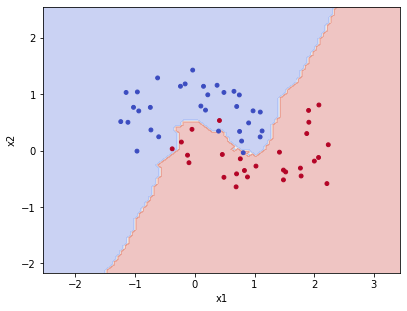

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
modell = KNeighborsClassifier(n_neighbors=9)
modell.fit(X_train, y_train)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3, cmap='coolwarm')
plt.scatter(X_test['x1'], X_test['x2'], c=y_test, cmap='coolwarm', s=15)
plt.show()
```

</details>

#### Aufgabe 1.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

X = pd.DataFrame({'x': [1, 2, 3, 4, 5, 6]})
y = [0, 0, 0, 1, 1, 1]
modell = KNeighborsClassifier(n_neighbors=6)
modell.fit(X, y)
print(modell.score(X, y))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
0.5
```

Mit `k = 6` sind bei jeder Vorhersage alle sechs Punkte Nachbarn: dreimal 0, dreimal 1. Bei Gleichstand nimmt scikit-learn die erste Klasse, also 0.
Das Modell sagt immer 0 voraus und liegt bei den drei Punkten der Klasse 0 richtig: `0.5`. Ein extremer Fall von Unteranpassung.

</details>

## 2. Entscheidungsbäume

#### Fragen mit ja oder nein

Ein **Entscheidungsbaum** ordnet ein Beispiel durch eine Folge von Fragen ein, z. B. „Ist `bluete_laenge <= 2.45`?“. Je nach Antwort geht es links oder rechts weiter,
bis ein **Blatt** erreicht ist, das die Klasse angibt. Beim Training sucht das Verfahren für jede Frage das Merkmal und die Grenze, die die Klassen am besten trennt.

- `DecisionTreeClassifier(max_depth=2, random_state=0)`: `max_depth` begrenzt die Anzahl der Fragen hintereinander (die **Tiefe**).
- `export_text(modell, feature_names=list(X.columns))` gibt den Baum als Text aus. Jede Zeile ist eine Frage oder ein Blatt (`class: ...`).

Bäume brauchen **kein Skalieren**: Jede Frage betrifft nur ein Merkmal.

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.tree import DecisionTreeClassifier, export_text

X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
modell = DecisionTreeClassifier(max_depth=2, random_state=0)
modell.fit(X, y)
print(export_text(modell, feature_names=list(X.columns)))
print(f'{modell.score(X, y):.3f}')

#### Den Baum zeichnen und die wichtigen Merkmale

- `plot_tree(modell, feature_names=..., class_names=..., filled=True)` zeichnet den Baum. In jedem Kasten stehen die Frage, `gini` (wie gemischt die Klassen
  dort noch sind, 0 = rein), `samples` (wie viele Trainingsbeispiele dort ankommen) und `value` (wie viele davon zu jeder Klasse gehören).
- `modell.feature_importances_` gibt an, wie viel jedes Merkmal zur Trennung beiträgt (zusammen 1).
- `modell.get_depth()` und `modell.get_n_leaves()` sind die Tiefe und die Anzahl der Blätter.

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
modell = DecisionTreeClassifier(max_depth=2, random_state=0)
modell.fit(X, y)
print(modell.get_depth(), modell.get_n_leaves())
print(pd.Series(modell.feature_importances_, index=X.columns).round(3))
plt.figure(figsize=(8, 5))
plot_tree(modell, feature_names=list(X.columns), class_names=list(modell.classes_), filled=True)
plt.show()

#### Tiefe Bäume lernen auswendig

Ohne `max_depth` wächst der Baum, bis jedes Blatt nur noch eine Klasse enthält. Dann ist er auf den Trainingsdaten perfekt, hat aber auch alle Zufälle
gelernt: Überanpassung wie bei k-NN mit `k = 1`. Die Entscheidungsgrenzen eines Baums bestehen aus waagerechten und senkrechten Stücken.

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.tree import DecisionTreeClassifier

for tiefe in [1, 3, 5, None]:
    modell = DecisionTreeClassifier(max_depth=tiefe, random_state=0)
    modell.fit(X_train, y_train)
    print(f'{tiefe} Tiefe {modell.get_depth()}, Blätter {modell.get_n_leaves()}: '
          f'Training {modell.score(X_train, y_train):.3f}, Test {modell.score(X_test, y_test):.3f}')

#### Aufgabe 2.1

Trainiere einen Entscheidungsbaum mit `max_depth=1` auf allen vier Iris-Maßen und gib ihn mit `export_text()` und seine Genauigkeit aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
|--- bluete_breite <= 0.80
|   |--- class: setosa
|--- bluete_breite >  0.80
|   |--- class: versicolor

0.667
```

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.tree import DecisionTreeClassifier, export_text
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.tree import DecisionTreeClassifier, export_text
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
modell = DecisionTreeClassifier(max_depth=1, random_state=0)
modell.fit(X, y)
print(export_text(modell, feature_names=list(X.columns)))
print(f'{modell.score(X, y):.3f}')
```

</details>

#### Aufgabe 2.2

Sage mit dem Iris-Baum der Tiefe 2 aus dem Beispiel die Arten der Blüten in der Tabelle `neu` voraus. Verfolge für die erste Blüte die Fragen im Text des Baums.

**Erwartete Ausgabe:**

```
['setosa' 'versicolor' 'virginica']
```

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.tree import DecisionTreeClassifier

X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
neu = pd.DataFrame({'kelch_laenge': [5.0, 6.0, 6.5], 'kelch_breite': [3.4, 2.9, 3.0],
                    'bluete_laenge': [1.5, 4.5, 5.6], 'bluete_breite': [0.2, 1.5, 2.1]})
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.tree import DecisionTreeClassifier

X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
neu = pd.DataFrame({'kelch_laenge': [5.0, 6.0, 6.5], 'kelch_breite': [3.4, 2.9, 3.0],
                    'bluete_laenge': [1.5, 4.5, 5.6], 'bluete_breite': [0.2, 1.5, 2.1]})
modell = DecisionTreeClassifier(max_depth=2, random_state=0)
modell.fit(X, y)
print(modell.predict(neu))
```

</details>

#### Aufgabe 2.3

Gib für Iris-Bäume mit `max_depth` von 1 bis 6 die Tiefe, die Anzahl der Blätter und die Genauigkeit auf Trainings- und Testdaten aus
(Aufteilung in der Zelle, 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1 2 0.700 0.617
2 3 0.978 0.867
3 4 0.989 0.950
4 5 1.000 0.950
5 5 1.000 0.950
6 5 1.000 0.950
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
from sklearn.tree import DecisionTreeClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
from sklearn.tree import DecisionTreeClassifier
for tiefe in range(1, 7):
    modell = DecisionTreeClassifier(max_depth=tiefe, random_state=0)
    modell.fit(X_train, y_train)
    print(f'{tiefe} {modell.get_n_leaves()} {modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 2.4

Gib für die Halbmond-Daten Bäume mit `max_depth` von 1 bis 10 die Genauigkeit auf Trainings- und Testdaten aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1 0.814 0.833
2 0.886 0.867
3 0.886 0.867
4 0.907 0.850
5 0.936 0.867
6 0.943 0.867
7 0.957 0.833
8 0.971 0.867
9 0.993 0.833
10 1.000 0.850
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.tree import DecisionTreeClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.tree import DecisionTreeClassifier
for tiefe in range(1, 11):
    modell = DecisionTreeClassifier(max_depth=tiefe, random_state=0)
    modell.fit(X_train, y_train)
    print(f'{tiefe} {modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 2.5

Trainiere einen Baum (`max_depth=3`) auf allen 13 Wein-Messwerten und gib die drei wichtigsten Merkmale mit ihrer Wichtigkeit aus
(`pd.Series(..., index=X.columns)`, absteigend sortiert mit `sort_values(ascending=False)`, 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
proline                         0.409
od280/od315_of_diluted_wines    0.333
flavanoids                      0.133
dtype: float64
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.tree import DecisionTreeClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.tree import DecisionTreeClassifier
modell = DecisionTreeClassifier(max_depth=3, random_state=0)
modell.fit(X, y)
wichtig = pd.Series(modell.feature_importances_, index=X.columns).sort_values(ascending=False)
print(wichtig.head(3).round(3))
```

</details>

#### Aufgabe 2.6

Zeichne den Wein-Baum mit `max_depth=2` mit `plot_tree()` (Merkmalsnamen, `class_names=['0', '1', '2']`, `filled=True`, Bildgröße 9 × 5).

**Erwartete Ausgabe:**



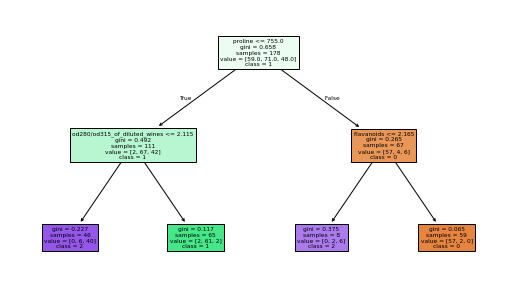

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
modell = DecisionTreeClassifier(max_depth=2, random_state=0)
modell.fit(X, y)
plt.figure(figsize=(9, 5))
plot_tree(modell, feature_names=list(X.columns), class_names=['0', '1', '2'], filled=True)
plt.show()
```

</details>

#### Aufgabe 2.7

Zeichne die Entscheidungsgrenzen eines Baums mit `max_depth=4` für die Halbmond-Daten (trainiert mit den Trainingsdaten) mit den Trainingspunkten darüber.
Die Grenzen bestehen nur aus waagerechten und senkrechten Stücken.

**Erwartete Ausgabe:**



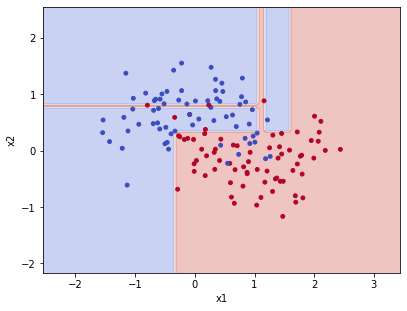

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
modell = DecisionTreeClassifier(max_depth=4, random_state=0)
modell.fit(X_train, y_train)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3, cmap='coolwarm')
plt.scatter(X_train['x1'], X_train['x2'], c=y_train, cmap='coolwarm', s=15)
plt.show()
```

</details>

#### Aufgabe 2.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

X = pd.DataFrame({'alter': [8, 10, 12, 15, 17, 30]})
y = ['Kind', 'Kind', 'Kind', 'Jugendlich', 'Jugendlich', 'Erwachsen']
modell = DecisionTreeClassifier(random_state=0)
modell.fit(X, y)
print(modell.score(X, y), modell.get_n_leaves())

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
1.0 3
```

Ohne `max_depth` wächst der Baum, bis jedes Blatt rein ist. Mit zwei Fragen (`alter <= 13.5` und `alter <= 23.5`) sind die drei Gruppen getrennt:
Alle Trainingsbeispiele werden richtig eingeordnet (`1.0`), und es gibt `3` Blätter.

</details>

## 3. Logistische Regression

#### Wahrscheinlichkeiten statt Mehrheiten

Die **logistische Regression** ist trotz ihres Namens ein Verfahren zur Klassifikation. Sie berechnet aus den Merkmalen eine gewichtete Summe
`z = w₁·x₁ + w₂·x₂ + ... + b` und macht daraus mit der **S-Kurve** `1 / (1 + e^(-z))` eine **Wahrscheinlichkeit** zwischen 0 und 1.
Ist sie größer als 0.5, wird die zweite Klasse vorhergesagt. Beim Training werden die Gewichte `w` und `b` so gewählt, dass die Wahrscheinlichkeiten
möglichst gut zu den Beispielen passen.

- `modell.predict_proba(X_neu)` gibt für jede Zeile die Wahrscheinlichkeiten aller Klassen (Spalten in der Reihenfolge von `modell.classes_`).
- `modell.coef_` sind die Gewichte, `modell.intercept_` ist `b`.

Wie bei k-NN sollten die Merkmale skaliert werden.

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
modell = LogisticRegression()
modell.fit(X, y)
print(modell.coef_.round(3), modell.intercept_.round(3))
neu = pd.DataFrame({'x1': [-1.0, 0.5, 2.0], 'x2': [1.0, 0.25, -0.5]})
print(modell.predict(neu))
print(modell.predict_proba(neu).round(3))

#### Die S-Kurve

Bei einem einzigen Merkmal sieht man die S-Kurve direkt: Für kleine Werte ist die Wahrscheinlichkeit fast 0, für große fast 1, dazwischen steigt sie an.
Die Stelle, an der sie 0.5 erreicht, ist die Entscheidungsgrenze. Beispiel: Wie wahrscheinlich besteht jemand eine Prüfung bei wie vielen Stunden Lernzeit?

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

lernen = pd.DataFrame({'stunden': [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7]})
bestanden = [0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1]
modell = LogisticRegression()
modell.fit(lernen, bestanden)
x = pd.DataFrame({'stunden': np.linspace(0, 8, 200)})
plt.plot(x['stunden'], modell.predict_proba(x)[:, 1])
plt.scatter(lernen['stunden'], bestanden, color='black')
plt.xlabel('Stunden')
plt.ylabel('Wahrscheinlichkeit für bestanden')
plt.show()

#### Aufgabe 3.1

Trainiere die logistische Regression für die Lernzeiten und gib die Wahrscheinlichkeit zu bestehen für 2, 4 und 6 Stunden aus
(Spalte 1 von `predict_proba()`, 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
[0.158 0.56  0.896]
```

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

lernen = pd.DataFrame({'stunden': [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7]})
bestanden = [0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.linear_model import LogisticRegression

lernen = pd.DataFrame({'stunden': [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7]})
bestanden = [0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1]
modell = LogisticRegression()
modell.fit(lernen, bestanden)
neu = pd.DataFrame({'stunden': [2, 4, 6]})
print(modell.predict_proba(neu)[:, 1].round(3))
```

</details>

#### Aufgabe 3.2

Ab wie vielen Stunden sagt das Modell „bestanden“ voraus? Dort ist `z = w · x + b = 0`, also `x = -b / w`. Gib die Grenze mit 2 Nachkommastellen aus.

**Erwartete Ausgabe:**

```
3.75
```

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

lernen = pd.DataFrame({'stunden': [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7]})
bestanden = [0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.linear_model import LogisticRegression

lernen = pd.DataFrame({'stunden': [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7]})
bestanden = [0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1]
modell = LogisticRegression()
modell.fit(lernen, bestanden)
w = modell.coef_[0, 0]
b = modell.intercept_[0]
print(f'{-b / w:.2f}')
```

</details>

#### Aufgabe 3.3

Trainiere eine Pipeline aus `StandardScaler` und logistischer Regression auf den Halbmond-Trainingsdaten und gib die Genauigkeit auf Trainings- und Testdaten aus
(3 Nachkommastellen). Eine gerade Grenze kann die Halbmonde nicht ganz trennen.

**Erwartete Ausgabe:**

```
0.829 0.850
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modell = make_pipeline(StandardScaler(), LogisticRegression())
modell.fit(X_train, y_train)
print(f'{modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 3.4

Zeichne die Entscheidungsgrenze der logistischen Regression für die Halbmond-Daten (trainiert mit allen Daten) mit den Punkten darüber.
Mit `response_method='predict_proba'` statt `'predict'` zeigt `DecisionBoundaryDisplay` die Wahrscheinlichkeit als Farbverlauf.

**Erwartete Ausgabe:**



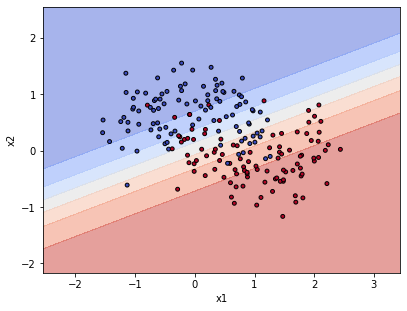

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
modell = LogisticRegression()
modell.fit(X, y)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict_proba', cmap='coolwarm', alpha=0.5)
plt.scatter(X['x1'], X['x2'], c=y, cmap='coolwarm', s=15, edgecolor='black')
plt.show()
```

</details>

#### Aufgabe 3.5

Trainiere eine skalierte logistische Regression auf den vier Iris-Maßen (Trainingsdaten aus der Zelle). Gib die Test-Genauigkeit (3 Nachkommastellen) und
für die erste Testblüte die Wahrscheinlichkeiten der drei Arten als Tabelle aus (`pd.DataFrame(..., columns=modell.classes_)`, 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0.933
```

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">setosa</th>
      <th style="text-align: right">versicolor</th>
      <th style="text-align: right">virginica</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">0.0</td>
      <td style="text-align: right">0.079</td>
      <td style="text-align: right">0.92</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modell = make_pipeline(StandardScaler(), LogisticRegression())
modell.fit(X_train, y_train)
print(f'{modell.score(X_test, y_test):.3f}')
pd.DataFrame(modell.predict_proba(X_test.head(1)), columns=modell.classes_).round(3)
```

</details>

#### Aufgabe 3.6

Bei welchen Iris-Testblüten ist sich das Modell der vorigen Aufgabe am **unsichersten**? Zeige die drei Testblüten mit der kleinsten höchsten Wahrscheinlichkeit an,
mit den Spalten `art`, `vorhersage` und `sicherheit` (die höchste Wahrscheinlichkeit, 3 Nachkommastellen).

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">art</th>
      <th style="text-align: right">vorhersage</th>
      <th style="text-align: right">sicherheit</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">126</th>
      <td style="text-align: right">virginica</td>
      <td style="text-align: right">virginica</td>
      <td style="text-align: right">0.534</td>
    </tr>
    <tr>
      <th style="text-align: right">123</th>
      <td style="text-align: right">virginica</td>
      <td style="text-align: right">virginica</td>
      <td style="text-align: right">0.547</td>
    </tr>
    <tr>
      <th style="text-align: right">56</th>
      <td style="text-align: right">versicolor</td>
      <td style="text-align: right">versicolor</td>
      <td style="text-align: right">0.556</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

iris = pd.read_csv('iris.csv')
X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modell = make_pipeline(StandardScaler(), LogisticRegression())
modell.fit(X_train, y_train)
ergebnis = pd.DataFrame({'art': y_test, 'vorhersage': modell.predict(X_test),
                         'sicherheit': modell.predict_proba(X_test).max(axis=1).round(3)})
ergebnis.sort_values('sicherheit').head(3)
```

</details>

#### Aufgabe 3.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression

X = pd.DataFrame({'x': [1, 2, 3, 7, 8, 9]})
y = ['nein', 'nein', 'nein', 'ja', 'ja', 'ja']
modell = LogisticRegression()
modell.fit(X, y)
print(modell.classes_)
print(modell.predict(pd.DataFrame({'x': [0, 4, 6, 10]})))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
['ja' 'nein']
['nein' 'nein' 'ja' 'ja']
```

- Die Klassen sind alphabetisch sortiert: `['ja' 'nein']`.
- Kleine `x` gehören zu `nein`, große zu `ja`. Weil die Beispiele symmetrisch liegen, ist die Grenze genau in der Mitte bei 5.
  0 und 4 liegen links davon, 6 und 10 rechts: `['nein' 'nein' 'ja' 'ja']`.

</details>

## 4. Neuronale Netze

#### Neuronen in Schichten

Ein **künstliches neuronales Netz** besteht aus vielen einfachen Recheneinheiten, den **Neuronen**. Jedes Neuron bildet wie die logistische Regression eine
gewichtete Summe seiner Eingaben und wendet darauf eine Funktion an (z. B. „negative Werte werden 0“). Die Neuronen sind in **Schichten** angeordnet:

- Die **Eingabeschicht** sind die Merkmale.
- Die **verborgenen Schichten** (*hidden layers*) rechnen weiter, jede mit den Ergebnissen der Schicht davor.
- Die **Ausgabeschicht** liefert die Wahrscheinlichkeiten der Klassen.

Beim Training werden die Gewichte in vielen kleinen Schritten verbessert (**Iterationen**): Das Netz sagt die Trainingsbeispiele vorher, misst den Fehler
(den **Verlust**, *loss*) und verändert die Gewichte so, dass der Fehler kleiner wird. Dadurch kann ein Netz auch gekrümmte Grenzen lernen.

`MLPClassifier(hidden_layer_sizes=(10,), max_iter=2000, learning_rate_init=0.01, random_state=0)` (*multi-layer perceptron*) hat eine verborgene Schicht mit 10 Neuronen,
`(20, 10)` wären zwei Schichten. `max_iter` begrenzt die Anzahl der Iterationen, `random_state` legt die zufälligen Startgewichte fest.
`learning_rate_init` (*Lernrate*) bestimmt, wie groß die Schritte beim Verbessern der Gewichte sind. Der Standardwert 0.001 ist für die wenigen
Halbmond-Punkte zu vorsichtig; hier wird deshalb immer `learning_rate_init=0.01` benutzt. Neuronale Netze brauchen skalierte Daten.

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(10,), max_iter=2000, learning_rate_init=0.01, random_state=0))
modell.fit(X_train, y_train)
print(f'Training {modell.score(X_train, y_train):.3f}, Test {modell.score(X_test, y_test):.3f}')

#### Den Lernverlauf ansehen

Das Netz in einer Pipeline erreicht man mit `modell[-1]` (dem letzten Schritt). `netz.loss_curve_` ist die Liste der Verluste nach jeder Iteration,
`netz.n_iter_` die Anzahl der Iterationen, bis das Training aufgehört hat, weil der Verlust kaum noch kleiner wurde. Gezeichnet sieht man, wie das Netz lernt.

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(10,), max_iter=2000, learning_rate_init=0.01, random_state=0))
modell.fit(X_train, y_train)
netz = modell[-1]
print(netz.n_iter_)
plt.plot(netz.loss_curve_)
plt.xlabel('Iteration')
plt.ylabel('Verlust')
plt.show()

#### Ziffern erkennen

`load_digits()` enthält 1797 kleine Bilder handgeschriebener Ziffern mit 8 × 8 Pixeln. `ziffern.images` sind die Bilder als 8 × 8-Arrays (Helligkeit 0 bis 16),
`ziffern.data` dieselben Bilder als Zeilen mit 64 Zahlen (die Merkmale), `ziffern.target` die richtigen Ziffern. `plt.imshow(bild, cmap='gray_r')`
zeigt ein Bild an (`gray_r`: dunkel auf hell).

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import matplotlib.pyplot as plt

print(X.shape, y[:10])
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(ziffern.images[i], cmap='gray_r')
    plt.axis('off')
plt.show()

#### Aufgabe 4.1

Vergleiche Netze mit einer verborgenen Schicht aus 2, 5, 10 und 50 Neuronen auf den Halbmond-Daten (skaliert, `max_iter=2000`, `learning_rate_init=0.01`, `random_state=0`).
Gib die Anzahl der Neuronen und die Genauigkeit auf Trainings- und Testdaten aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
2 0.829 0.867
5 0.829 0.867
10 0.907 0.950
50 0.943 0.950
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
for neuronen in [2, 5, 10, 50]:
    modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(neuronen,), max_iter=2000, learning_rate_init=0.01, random_state=0))
    modell.fit(X_train, y_train)
    print(f'{neuronen} {modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 4.2

Trainiere ein Netz mit zwei verborgenen Schichten (`(20, 10)`) auf den Halbmond-Daten (skaliert, `max_iter=2000`, `learning_rate_init=0.01`, `random_state=0`) und gib die Test-Genauigkeit aus.
Gib außerdem die Formen der Gewichtsmatrizen aus (`[w.shape for w in netz.coefs_]`): von 2 Eingaben zu 20 Neuronen, von 20 zu 10, von 10 zur Ausgabe.

**Erwartete Ausgabe:**

```
0.933
[(2, 20), (20, 10), (10, 1)]
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(20, 10), max_iter=2000, learning_rate_init=0.01, random_state=0))
modell.fit(X_train, y_train)
print(f'{modell.score(X_test, y_test):.3f}')
netz = modell[-1]
print([w.shape for w in netz.coefs_])
```

</details>

#### Aufgabe 4.3

Wie viele Gewichte hat das Netz der vorigen Aufgabe insgesamt? Zähle die Einträge aller Matrizen in `netz.coefs_` (`w.size`) und aller Arrays in `netz.intercepts_`
(die `b`-Werte der Neuronen) und gib beide Summen und die Gesamtzahl aus.

**Erwartete Ausgabe:**

```
250 31 281
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(20, 10), max_iter=2000, learning_rate_init=0.01, random_state=0))
modell.fit(X_train, y_train)
netz = modell[-1]
gewichte = sum([w.size for w in netz.coefs_])
b_werte = sum([b.size for b in netz.intercepts_])
print(gewichte, b_werte, gewichte + b_werte)
```

</details>

#### Aufgabe 4.4

Zeichne die Entscheidungsgrenzen des Netzes mit 10 Neuronen für die Halbmond-Daten (trainiert mit den Trainingsdaten) mit den Trainingspunkten darüber.
Die Grenze ist gekrümmt.

**Erwartete Ausgabe:**



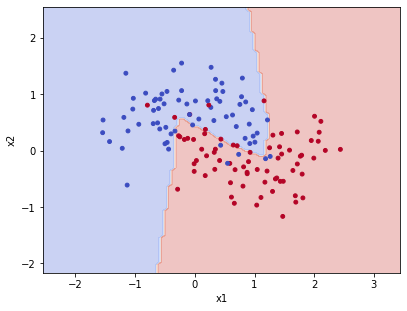

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(10,), max_iter=2000, learning_rate_init=0.01, random_state=0))
modell.fit(X_train, y_train)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3, cmap='coolwarm')
plt.scatter(X_train['x1'], X_train['x2'], c=y_train, cmap='coolwarm', s=15)
plt.show()
```

</details>

#### Aufgabe 4.5

Zeige die ersten 5 Bilder der Ziffern-**Testdaten** nebeneinander an. Die Testdaten sind Zeilen mit 64 Zahlen; `X_test[i].reshape(8, 8)` macht daraus wieder ein Bild.
Schreibe die richtige Ziffer als Titel über jedes Bild.

**Erwartete Ausgabe:**



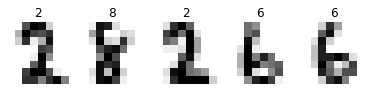

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import matplotlib.pyplot as plt
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i].reshape(8, 8), cmap='gray_r')
    plt.title(y_test[i])
    plt.axis('off')
plt.show()
```

</details>

#### Aufgabe 4.6

Trainiere ein Netz mit einer verborgenen Schicht aus 64 Neuronen auf den Ziffern-Trainingsdaten (skaliert, `max_iter=300`, `random_state=0`; das Training dauert
einige Sekunden). Gib die Test-Genauigkeit aus (3 Nachkommastellen) und die Vorhersagen für die ersten 10 Testbilder neben den richtigen Ziffern.

**Erwartete Ausgabe:**

```
0.971
[2 8 2 6 6 7 1 9 8 5]
[2 8 2 6 6 7 1 9 8 5]
```

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0))
modell.fit(X_train, y_train)
print(f'{modell.score(X_test, y_test):.3f}')
print(modell.predict(X_test[:10]))
print(y_test[:10])
```

</details>

#### Aufgabe 4.7

Zeige alle Testbilder an, die das Ziffern-Netz der vorigen Aufgabe falsch erkennt (höchstens 12, in einer Reihe), mit dem Titel `richtig→vorhergesagt`, z. B. `3→8`.

**Erwartete Ausgabe:**



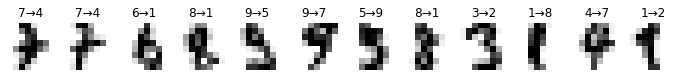

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0))
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
falsch = np.where(vorhersage != y_test)[0][:12]
plt.figure(figsize=(12, 2))
for nr, i in enumerate(falsch):
    plt.subplot(1, len(falsch), nr + 1)
    plt.imshow(X_test[i].reshape(8, 8), cmap='gray_r')
    plt.title(f'{y_test[i]}→{vorhersage[i]}')
    plt.axis('off')
plt.show()
```

</details>

#### Aufgabe 4.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from sklearn.neural_network import MLPClassifier

netz = MLPClassifier(hidden_layer_sizes=(5, 3))
print(len(netz.hidden_layer_sizes))
print(netz.hidden_layer_sizes[0] * 4 + netz.hidden_layer_sizes[0] * netz.hidden_layer_sizes[1])

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
2
35
```

- `(5, 3)` sind zwei verborgene Schichten: `2`.
- Bei 4 Eingaben hat die erste Gewichtsmatrix `4 · 5 = 20` Einträge, die zweite `5 · 3 = 15`, zusammen `35`.
  (Das Netz ist hier noch nicht trainiert; die Zahl ist nur aus den Schichtgrößen berechnet.)

</details>

## 5. Kreuzvalidierung und Gittersuche

#### Kreuzvalidierung: `cross_val_score()`

Eine einzige Aufteilung in Trainings- und Testdaten hängt vom Zufall ab (Notebook 1, Abschnitt 4). Bei der **Kreuzvalidierung** werden die Daten in `cv` gleich große
Teile (*folds*) zerlegt. Jeder Teil ist einmal die Testmenge, die anderen dienen zum Training. Man erhält `cv` Genauigkeiten und nimmt den Mittelwert.

`cross_val_score(modell, X, y, cv=5)` trainiert und prüft das Modell so fünfmal und gibt die fünf Genauigkeiten als Array zurück.
Bei der Klassifikation achtet es darauf, dass in jedem Teil alle Klassen etwa gleich oft vorkommen.

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
werte = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=0), X, y, cv=5)
print(werte.round(3))
print(f'{werte.mean():.3f} ± {werte.std():.3f}')

#### Gittersuche: `GridSearchCV`

Welches `k`, welche Tiefe ist am besten? `GridSearchCV(modell, gitter, cv=5)` probiert alle Kombinationen aus dem Dictionary `gitter` aus und bewertet jede mit
Kreuzvalidierung. Nach `fit()` stehen in `best_params_` die besten Einstellungen und in `best_score_` deren mittlere Genauigkeit.
Mit `best_estimator_` erhält man das beste Modell, neu trainiert mit allen Daten von `fit()`.

Bei einer Pipeline schreibt man vor den Namen der Einstellung den Namen des Schritts (Klassenname in Kleinbuchstaben) und zwei Unterstriche:
`'kneighborsclassifier__n_neighbors'`.

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

suche = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': [1, 3, 5, 9, 15, 25]}, cv=5)
suche.fit(X_train, y_train)
print(suche.best_params_)
print(f'{suche.best_score_:.3f}')
print(f'{suche.best_estimator_.score(X_test, y_test):.3f}')

#### Aufgabe 5.1

Vergleiche mit 5-facher Kreuzvalidierung auf den vier Iris-Maßen: k-NN (`k = 5`), einen Baum (`max_depth=3`) und eine skalierte logistische Regression.
Gib für jedes Modell den Namen und die mittlere Genauigkeit aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
k-NN 0.973
Baum 0.960
logistisch 0.960
```

In [ ]:
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

iris = pd.read_csv('iris.csv')
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = iris[['kelch_laenge', 'kelch_breite', 'bluete_laenge', 'bluete_breite']]
y = iris['art']
modelle = {'k-NN': KNeighborsClassifier(n_neighbors=5),
           'Baum': DecisionTreeClassifier(max_depth=3, random_state=0),
           'logistisch': make_pipeline(StandardScaler(), LogisticRegression())}
for name, modell in modelle.items():
    print(name, f'{cross_val_score(modell, X, y, cv=5).mean():.3f}')
```

</details>

#### Aufgabe 5.2

Gib für die Wein-Daten die fünf Genauigkeiten der Kreuzvalidierung einer skalierten k-NN-Pipeline (`k = 5`) aus (3 Nachkommastellen) und ihren Mittelwert.

**Erwartete Ausgabe:**

```
[0.944 0.944 0.972 1.    0.886]
0.949
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
werte = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), X, y, cv=5)
print(werte.round(3))
print(f'{werte.mean():.3f}')
```

</details>

#### Aufgabe 5.3

Finde mit `GridSearchCV` (5-fach) die beste Tiefe eines Baums für die Halbmond-Trainingsdaten unter `max_depth` von 1 bis 10. Gib die beste Tiefe,
die mittlere Genauigkeit der Kreuzvalidierung und die Genauigkeit des besten Modells auf den Testdaten aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
4
0.879 0.850
```

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
suche = GridSearchCV(DecisionTreeClassifier(random_state=0), {'max_depth': list(range(1, 11))}, cv=5)
suche.fit(X_train, y_train)
print(suche.best_params_['max_depth'])
print(f'{suche.best_score_:.3f} {suche.best_estimator_.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 5.4

Suche mit `GridSearchCV` für eine Pipeline aus `StandardScaler` und k-NN auf den Wein-Daten das beste `k` unter 1, 3, 5, 7, 9, 15 und die beste Gewichtung
(`'uniform'` oder `'distance'`). Gib die besten Einstellungen und die mittlere Genauigkeit aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
{'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__weights': 'uniform'}
0.967
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
gitter = {'kneighborsclassifier__n_neighbors': [1, 3, 5, 7, 9, 15],
          'kneighborsclassifier__weights': ['uniform', 'distance']}
suche = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()), gitter, cv=5)
suche.fit(X, y)
print(suche.best_params_)
print(f'{suche.best_score_:.3f}')
```

</details>

#### Aufgabe 5.5

Zeige für die Baum-Suche auf den Halbmond-Daten (Tiefen 1 bis 10) eine Tabelle mit den Spalten `param_max_depth`, `mean_test_score` und `rank_test_score`
aus `pd.DataFrame(suche.cv_results_)` an (Genauigkeit auf 3 Nachkommastellen gerundet).

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">param_max_depth</th>
      <th style="text-align: right">mean_test_score</th>
      <th style="text-align: right">rank_test_score</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">1</td>
      <td style="text-align: right">0.800</td>
      <td style="text-align: right">10</td>
    </tr>
    <tr>
      <th style="text-align: right">1</th>
      <td style="text-align: right">2</td>
      <td style="text-align: right">0.864</td>
      <td style="text-align: right">3</td>
    </tr>
    <tr>
      <th style="text-align: right">2</th>
      <td style="text-align: right">3</td>
      <td style="text-align: right">0.864</td>
      <td style="text-align: right">3</td>
    </tr>
    <tr>
      <th style="text-align: right">3</th>
      <td style="text-align: right">4</td>
      <td style="text-align: right">0.879</td>
      <td style="text-align: right">1</td>
    </tr>
    <tr>
      <th style="text-align: right">4</th>
      <td style="text-align: right">5</td>
      <td style="text-align: right">0.871</td>
      <td style="text-align: right">2</td>
    </tr>
    <tr>
      <th style="text-align: right">5</th>
      <td style="text-align: right">6</td>
      <td style="text-align: right">0.857</td>
      <td style="text-align: right">5</td>
    </tr>
    <tr>
      <th style="text-align: right">6</th>
      <td style="text-align: right">7</td>
      <td style="text-align: right">0.850</td>
      <td style="text-align: right">6</td>
    </tr>
    <tr>
      <th style="text-align: right">7</th>
      <td style="text-align: right">8</td>
      <td style="text-align: right">0.850</td>
      <td style="text-align: right">6</td>
    </tr>
    <tr>
      <th style="text-align: right">8</th>
      <td style="text-align: right">9</td>
      <td style="text-align: right">0.850</td>
      <td style="text-align: right">6</td>
    </tr>
    <tr>
      <th style="text-align: right">9</th>
      <td style="text-align: right">10</td>
      <td style="text-align: right">0.850</td>
      <td style="text-align: right">6</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
suche = GridSearchCV(DecisionTreeClassifier(random_state=0), {'max_depth': list(range(1, 11))}, cv=5)
suche.fit(X_train, y_train)
ergebnisse = pd.DataFrame(suche.cv_results_)[['param_max_depth', 'mean_test_score', 'rank_test_score']]
ergebnisse.round(3)
```

</details>

#### Aufgabe 5.6

Zeichne für die Halbmond-Trainingsdaten die mittlere Genauigkeit der Kreuzvalidierung (5-fach) von k-NN für `k` von 1 bis 50 als Linie (x-Achse: `k`).

**Erwartete Ausgabe:**



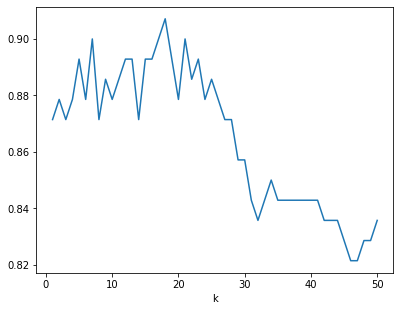

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
werte_k = range(1, 51)
mittel = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in werte_k]
plt.plot(werte_k, mittel)
plt.xlabel('k')
plt.show()
```

</details>

#### Aufgabe 5.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np

werte = np.array([1.0, 0.9, 1.0, 0.8, 1.0])
print(f'{werte.mean():.2f}')
print(len(werte))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
0.94
5
```

So sieht das Ergebnis einer 5-fachen Kreuzvalidierung aus: fünf Genauigkeiten, eine pro Teil (`5`).
Ihr Mittelwert ist `(1 + 0.9 + 1 + 0.8 + 1) / 5 = 0.94`.

</details>

## 6. Precision und Recall

#### Wenn die Genauigkeit täuscht

Die Datei `load_breast_cancer` enthält 569 Gewebeproben mit 30 Messwerten und der Diagnose (0: bösartig, 1: gutartig). Hier ist nicht jeder Fehler gleich schlimm:
Eine bösartige Probe als gutartig einzuordnen ist viel schlimmer als umgekehrt. Für eine Klasse (hier: bösartig) betrachtet man deshalb zwei Werte:

- **Precision** (*Präzision*): Von den als bösartig vorhergesagten Proben, wie viele sind wirklich bösartig?
- **Recall** (*Trefferquote*, *Sensitivität*): Von den wirklich bösartigen Proben, wie viele wurden gefunden?

`precision_score(y_test, vorhersage, pos_label=0)` und `recall_score(...)` berechnen sie für die Klasse `pos_label`.
`classification_report(y_test, vorhersage)` zeigt beide (und den **f1-score**, einen Mittelwert aus beiden) für alle Klassen.

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, classification_report

modell = make_pipeline(StandardScaler(), LogisticRegression())
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
print(f'Genauigkeit {modell.score(X_test, y_test):.3f}')
print(f'Precision {precision_score(y_test, vorhersage, pos_label=0):.3f}')
print(f'Recall    {recall_score(y_test, vorhersage, pos_label=0):.3f}')
print(classification_report(y_test, vorhersage, target_names=['bösartig', 'gutartig']))

#### Die Schwelle verschieben

Normalerweise wird die Klasse mit der größeren Wahrscheinlichkeit vorhergesagt, die Schwelle ist also 0.5. Will man möglichst **alle** bösartigen Proben finden,
erklärt man eine Probe schon ab einer kleineren Wahrscheinlichkeit für bösartig zum Verdachtsfall. Dann steigt der Recall, aber die Precision sinkt,
weil es mehr Fehlalarme gibt.

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score

modell = make_pipeline(StandardScaler(), LogisticRegression())
modell.fit(X_train, y_train)
p_boesartig = modell.predict_proba(X_test)[:, 0]
for schwelle in [0.5, 0.2, 0.05]:
    vorhersage = (p_boesartig < schwelle).astype(int)   # 1 (gutartig), wenn bösartig unwahrscheinlich
    print(schwelle, f'{precision_score(y_test, vorhersage, pos_label=0):.3f}', f'{recall_score(y_test, vorhersage, pos_label=0):.3f}')

#### Aufgabe 6.1

Gib aus, wie viele bösartige und gutartige Proben es insgesamt und in den Testdaten gibt (`value_counts().sort_index()`).

**Erwartete Ausgabe:**

```
target
0    212
1    357
Name: count, dtype: int64
target
0    53
1    90
Name: count, dtype: int64
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print(y.value_counts().sort_index())
print(y_test.value_counts().sort_index())
```

</details>

#### Aufgabe 6.2

Ein „Modell“, das immer „gutartig“ vorhersagt, wäre auf diesen Testdaten schon ziemlich genau. Berechne seine Genauigkeit und seinen Recall für bösartig
(`vorhersage = np.ones(len(y_test), dtype=int)`, 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0.629
0.000
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
import numpy as np
from sklearn.metrics import accuracy_score, recall_score
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
import numpy as np
from sklearn.metrics import accuracy_score, recall_score
vorhersage = np.ones(len(y_test), dtype=int)
print(f'{accuracy_score(y_test, vorhersage):.3f}')
print(f'{recall_score(y_test, vorhersage, pos_label=0):.3f}')
```

</details>

#### Aufgabe 6.3

Gib für die skalierte logistische Regression aus dem Beispiel die Konfusionsmatrix der Testdaten aus. Wie viele bösartige Proben wurden übersehen
(Zeile 0, Spalte 1)? Gib die Zahl in einer eigenen Zeile aus.

**Erwartete Ausgabe:**

```
[[50  3]
 [ 3 87]]
3
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
modell = make_pipeline(StandardScaler(), LogisticRegression())
modell.fit(X_train, y_train)
matrix = confusion_matrix(y_test, modell.predict(X_test))
print(matrix)
print(matrix[0, 1])
```

</details>

#### Aufgabe 6.4

Berechne Precision und Recall für bösartig aus der Konfusionsmatrix der vorigen Aufgabe selbst: Precision = `matrix[0, 0] / (matrix[0, 0] + matrix[1, 0])`,
Recall = `matrix[0, 0] / (matrix[0, 0] + matrix[0, 1])` (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0.943
0.943
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
modell = make_pipeline(StandardScaler(), LogisticRegression())
modell.fit(X_train, y_train)
matrix = confusion_matrix(y_test, modell.predict(X_test))
print(f'{matrix[0, 0] / (matrix[0, 0] + matrix[1, 0]):.3f}')
print(f'{matrix[0, 0] / (matrix[0, 0] + matrix[0, 1]):.3f}')
```

</details>

#### Aufgabe 6.5

Vergleiche k-NN (skaliert, `k = 5`), einen Baum (`max_depth=4`) und die skalierte logistische Regression auf den Testdaten: Gib für jedes Modell den Namen,
die Genauigkeit und den Recall für bösartig aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
k-NN 0.951 0.887
Baum 0.909 0.925
logistisch 0.958 0.943
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score
modelle = {'k-NN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
           'Baum': DecisionTreeClassifier(max_depth=4, random_state=0),
           'logistisch': make_pipeline(StandardScaler(), LogisticRegression())}
for name, modell in modelle.items():
    modell.fit(X_train, y_train)
    vorhersage = modell.predict(X_test)
    print(name, f'{modell.score(X_test, y_test):.3f}', f'{recall_score(y_test, vorhersage, pos_label=0):.3f}')
```

</details>

#### Aufgabe 6.6

Welche Schwelle braucht man, damit **alle** bösartigen Testproben gefunden werden (Recall 1)? Probiere die Schwellen 0.5, 0.4, 0.3, ..., 0.01 (`np.arange(0.5, 0, -0.01)`)
und gib die erste Schwelle mit Recall 1 und die Precision dort aus (2 bzw. 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0.09 0.828
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import precision_score, recall_score
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

daten = load_breast_cancer(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']     # 0: bösartig, 1: gutartig
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import precision_score, recall_score
modell = make_pipeline(StandardScaler(), LogisticRegression())
modell.fit(X_train, y_train)
p_boesartig = modell.predict_proba(X_test)[:, 0]
for schwelle in np.arange(0.5, 0, -0.01):
    vorhersage = (p_boesartig < schwelle).astype(int)
    if recall_score(y_test, vorhersage, pos_label=0) == 1:
        print(f'{schwelle:.2f} {precision_score(y_test, vorhersage, pos_label=0):.3f}')
        break
```

</details>

#### Aufgabe 6.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from sklearn.metrics import precision_score, recall_score

richtig =    ['spam', 'spam', 'spam', 'ok', 'ok', 'ok', 'ok', 'ok']
vorhersage = ['spam', 'ok',   'ok',   'ok', 'ok', 'ok', 'ok', 'spam']
print(precision_score(richtig, vorhersage, pos_label='spam'))
print(recall_score(richtig, vorhersage, pos_label='spam'))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
0.5
0.3333333333333333
```

- Als `spam` vorhergesagt wurden die erste und die letzte Nachricht. Nur die erste ist wirklich Spam: Precision `1 / 2 = 0.5`.
- Wirklich Spam sind die ersten drei. Gefunden wurde davon nur eine: Recall `1 / 3 ≈ 0.333`, ausgegeben als `0.3333333333333333`.

</details>

## 7. Gemischte Übungen

#### Aufgabe 7.1

Vergleiche vier Verfahren auf den Wein-Daten mit 5-facher Kreuzvalidierung: skaliertes k-NN (`k = 5`), Baum (`max_depth=4`), skalierte logistische Regression und
skaliertes neuronales Netz (`(20,)`, `max_iter=2000`, `random_state=0`). Gib Namen und mittlere Genauigkeit aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
k-NN 0.949
Baum 0.916
logistisch 0.983
Netz 0.978
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_wine

wein = load_wine(as_frame=True).frame
X = wein.drop(columns='target')
y = wein['target']
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
modelle = {'k-NN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
           'Baum': DecisionTreeClassifier(max_depth=4, random_state=0),
           'logistisch': make_pipeline(StandardScaler(), LogisticRegression()),
           'Netz': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(20,), max_iter=2000, random_state=0))}
for name, modell in modelle.items():
    print(name, f'{cross_val_score(modell, X, y, cv=5).mean():.3f}')
```

</details>

#### Aufgabe 7.2

Zeichne die Entscheidungsgrenzen von vier Verfahren für die Halbmond-Daten nebeneinander (`plt.figure(figsize=(12, 3))`, `ax = plt.subplot(1, 4, i)`,
`DecisionBoundaryDisplay.from_estimator(..., ax=ax)`): k-NN (`k = 9`), Baum (`max_depth=4`), logistische Regression und Netz (`(10,)`, skaliert, `max_iter=2000`,
`learning_rate_init=0.01`, `random_state=0`). Trainiert wird mit den Trainingsdaten. Schreibe den Namen und die Test-Genauigkeit (2 Nachkommastellen) als Titel.

**Erwartete Ausgabe:**



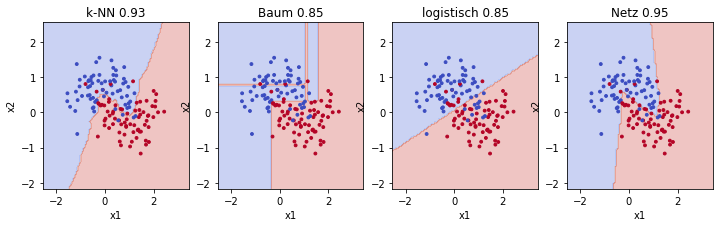

In [ ]:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
modelle = {'k-NN': KNeighborsClassifier(n_neighbors=9),
           'Baum': DecisionTreeClassifier(max_depth=4, random_state=0),
           'logistisch': LogisticRegression(),
           'Netz': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(10,), max_iter=2000, learning_rate_init=0.01, random_state=0))}
plt.figure(figsize=(12, 3))
for i, (name, modell) in enumerate(modelle.items(), start=1):
    modell.fit(X_train, y_train)
    ax = plt.subplot(1, 4, i)
    DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3, cmap='coolwarm', ax=ax)
    ax.scatter(X_train['x1'], X_train['x2'], c=y_train, cmap='coolwarm', s=8)
    ax.set_title(f'{name} {modell.score(X_test, y_test):.2f}')
plt.show()
```

</details>

#### Aufgabe 7.3

Erkenne Ziffern mit einem Entscheidungsbaum: Suche mit `GridSearchCV` (5-fach, Ziffern-Trainingsdaten) die beste Tiefe unter 5, 10, 15 und 20 und gib die beste Tiefe
und die Test-Genauigkeit des besten Baums aus (3 Nachkommastellen). Vergleiche mit dem neuronalen Netz aus Abschnitt 4.

**Erwartete Ausgabe:**

```
10
0.822
```

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
suche = GridSearchCV(DecisionTreeClassifier(random_state=0), {'max_depth': [5, 10, 15, 20]}, cv=5)
suche.fit(X_train, y_train)
print(suche.best_params_['max_depth'])
print(f'{suche.best_estimator_.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 7.4

Welche Ziffern verwechselt das neuronale Netz (`(64,)`, skaliert, `max_iter=300`, `random_state=0`) am häufigsten? Gib die Konfusionsmatrix der Testdaten aus
und danach das Paar (richtige Ziffer, vorhergesagte Ziffer) mit der größten Zahl außerhalb der Diagonalen (bei mehreren gleich großen das erste). Setze dazu die Diagonale mit `np.fill_diagonal(matrix, 0)` auf 0
und benutze `np.unravel_index(matrix.argmax(), matrix.shape)`.

**Erwartete Ausgabe:**

```
[[37  0  0  0  0  0  0  0  0  0]
 [ 0 41  1  0  0  0  0  0  1  0]
 [ 0  0 44  0  0  0  0  0  0  0]
 [ 0  0  1 44  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  2  0  0]
 [ 0  0  0  0  0 47  0  0  0  1]
 [ 0  1  0  0  0  0 51  0  0  0]
 [ 0  0  0  0  2  0  0 46  0  0]
 [ 0  2  0  0  0  0  0  0 46  0]
 [ 0  0  0  0  0  1  0  1  0 45]]
4 7 2
```

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

ziffern = load_digits()
X, y = ziffern.data, ziffern.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
modell = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0))
modell.fit(X_train, y_train)
matrix = confusion_matrix(y_test, modell.predict(X_test))
print(matrix)
np.fill_diagonal(matrix, 0)
richtig, vorhergesagt = np.unravel_index(matrix.argmax(), matrix.shape)
print(richtig, vorhergesagt, matrix[richtig, vorhergesagt])
```

</details>

#### Aufgabe 7.5

Erfinde eigene Daten mit `make_moons`, `make_circles` (zwei ineinanderliegende Ringe, z. B. `make_circles(n_samples=200, noise=0.1, factor=0.5, random_state=0)`)
oder `make_blobs` und finde mit Kreuzvalidierung heraus, welches Verfahren am besten passt. Zeichne die Entscheidungsgrenzen des besten.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import make_circles
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

X, y = make_circles(n_samples=200, noise=0.1, factor=0.5, random_state=0)
X = pd.DataFrame(X, columns=['x1', 'x2'])
for name, modell in {'k-NN': KNeighborsClassifier(n_neighbors=9), 'logistisch': LogisticRegression()}.items():
    print(name, f'{cross_val_score(modell, X, y, cv=5).mean():.3f}')
modell = KNeighborsClassifier(n_neighbors=9)
modell.fit(X, y)
DecisionBoundaryDisplay.from_estimator(modell, X, response_method='predict', alpha=0.3, cmap='coolwarm')
plt.scatter(X['x1'], X['x2'], c=y, cmap='coolwarm', s=15)
plt.show()
```

</details>